# TFG — Notebook final (IS ajustado + export + gráficos)

Este notebook implementa:

- **Simulación** del subyacente con volatilidad con cambio de régimen (cadena de Markov 2-estados).
- **Europea**: Monte Carlo estándar vs Monte Carlo con Muestreo por Importancia (IS).
- **Americana**: Longstaff–Schwartz (LSM) estándar y **LSM+IS correcto** (cambio de medida incorporado en la regresión mediante \(W_\tau/W_t\)).

Incluye:
- **Diagnósticos** de pesos (ESS) para evitar IS degenerado.
- **Export** de resultados a CSV y **gráficos** a PNG en la carpeta `outputs/`.

> Nota: IS es muy sensible a la elección del parámetro de inclinación (tilt). Aquí se elige **por (K,T,P)** y se **acota** para evitar explosión de varianza.


In [1]:
import numpy as np
import pandas as pd
import time
from dataclasses import dataclass
import matplotlib.pyplot as plt
from pathlib import Path

np.set_printoptions(suppress=True, precision=6)

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)
print("Directorio de salida:", OUT_DIR.resolve())


Directorio de salida: C:\Users\Usuario\GitHub\ucm\TFG\outputs


In [2]:
# =========================
# 1) Parámetros del estudio
# =========================
S0 = 100.0

# Tipo libre de riesgo y yield de dividendos continuo (q)
r = 0.03
q_main = 0.02     # caso principal: call americana con dividendos
q_sanity = 0.00   # sanity: sin dividendos (call americana ~ europea)

# Volatilidades por régimen (baja/alta)
sigma_L = 0.18
sigma_H = 0.40

# Matrices de transición (2 estados)
P_persistente = np.array([[0.95, 0.05],
                          [0.10, 0.90]])
P_menos_persistente = np.array([[0.85, 0.15],
                                [0.20, 0.80]])

Ps = {"persistente": P_persistente,
      "menos_persistente": P_menos_persistente}

# Grid de strikes y vencimientos
Ks = [90.0, 100.0, 110.0, 120.0]
Ts = [0.25, 1.0, 2.0]
steps_per_year = 252

# Número de simulaciones
M_std = 50_000
M_is  = 50_000

seed_base = 2026

print("Escenarios totales:", len(Ps)*len(Ks)*len(Ts))


Escenarios totales: 24


In [ ]:
def simulate_asset_paths_regime_switching_IS_logW(
    S0, T, n_steps, n_paths, market, regime, lam, x0=0, seed=42
):
    """Simula bajo Q~ con Z_tilt = Z + lam. Devuelve log-weights acumulados logW_t = log(dQ/dQ~)."""
    validate_params(regime, market)
    dt = T / n_steps

    X = simulate_markov_regimes(regime.P, n_paths, n_steps, x0=x0, seed=seed)
    rng = np.random.default_rng(seed + 1)
    Z = rng.standard_normal((n_paths, n_steps))
    Z_tilt = Z + lam

    S = np.empty((n_paths, n_steps + 1), float)
    S[:, 0] = S0

    # Para N(0,1) vs N(lam,1): w = exp(-lam*z - 0.5*lam^2)
    logW = np.zeros((n_paths, n_steps + 1), float)
    logw_step = -lam * Z - 0.5 * (lam**2)

    sig_states = np.asarray(regime.sigma, float)

    for t in range(n_steps):
        sig = sig_states[X[:, t]]
        drift = (market.r - market.q - 0.5 * sig**2) * dt
        diff  = sig * np.sqrt(dt) * Z_tilt[:, t]
        S[:, t+1] = S[:, t] * np.exp(drift + diff)
        logW[:, t+1] = logW[:, t] + logw_step[:, t]

    return S, X, logW


def ess_from_logw(logw):
    """ESS estable a partir de log-weights finales."""
    c = np.max(logw)
    w = np.exp(logw - c)
    s1 = np.sum(w)
    s2 = np.sum(w*w)
    ESS = (s1*s1)/s2
    return ESS


In [4]:
# =========================
# 3) Pricing: Europea (MC / IS)
# =========================
def price_european_call_mc(S_T, K, r, T):
    payoff = np.maximum(S_T-K, 0.0)
    contrib = np.exp(-r*T)*payoff
    price = contrib.mean()
    se = contrib.std(ddof=1)/np.sqrt(contrib.size)
    return price, se, price-1.96*se, price+1.96*se

def price_european_call_mc_weighted(S_T, W_T, K, r, T):
    payoff = np.maximum(S_T-K, 0.0)
    contrib = np.exp(-r*T)*W_T*payoff
    price = contrib.mean()
    se = contrib.std(ddof=1)/np.sqrt(contrib.size)
    return price, se, price-1.96*se, price+1.96*se


In [12]:
def simulate_asset_paths_regime_switching_IS_logW(
    S0, T, n_steps, n_paths, market, regime, lam, x0=0, seed=42
):
    """Simula bajo Q~ con Z_tilt = Z + lam. Devuelve log-weights acumulados logW_t = log(dQ/dQ~)."""
    validate_params(regime, market)
    dt = T / n_steps

    X = simulate_markov_regimes(regime.P, n_paths, n_steps, x0=x0, seed=seed)
    rng = np.random.default_rng(seed + 1)
    Z = rng.standard_normal((n_paths, n_steps))
    Z_tilt = Z + lam

    S = np.empty((n_paths, n_steps + 1), float)
    S[:, 0] = S0

    # Para N(0,1) vs N(lam,1): w = exp(-lam*z - 0.5*lam^2)
    logW = np.zeros((n_paths, n_steps + 1), float)
    logw_step = -lam * Z - 0.5 * (lam**2)

    sig_states = np.asarray(regime.sigma, float)

    for t in range(n_steps):
        sig = sig_states[X[:, t]]
        drift = (market.r - market.q - 0.5 * sig**2) * dt
        diff  = sig * np.sqrt(dt) * Z_tilt[:, t]
        S[:, t+1] = S[:, t] * np.exp(drift + diff)
        logW[:, t+1] = logW[:, t] + logw_step[:, t]

    return S, X, logW


def ess_from_logw(logw):
    """ESS estable a partir de log-weights finales."""
    c = np.max(logw)
    w = np.exp(logw - c)
    s1 = np.sum(w)
    s2 = np.sum(w*w)
    ESS = (s1*s1)/s2
    return ESS


In [13]:
S_is, X_is, logW = simulate_asset_paths_regime_switching_IS_logW(...)
logW_T = logW[:, -1]
ESS_T = ess_from_logw(logW_T)
ESS_frac = ESS_T / len(logW_T)
use_is = (ESS_frac >= 0.05)


TypeError: simulate_asset_paths_regime_switching_IS_logW() missing 6 required positional arguments: 'T', 'n_steps', 'n_paths', 'market', 'regime', and 'lam'

In [6]:
# =========================
# 5) Sanity checks
# =========================
def sanity_check():
    P=Ps["persistente"]
    regime=RegimeParams(sigma=np.array([sigma_L,sigma_H]), P=P)
    T=1.0; K=100.0
    n_steps=int(steps_per_year*T)
    market0=MarketParams(r=r,q=q_sanity)

    S, X = simulate_asset_paths_regime_switching(S0,T,n_steps,30_000,market0,regime,seed=seed_base)
    theo=S0*np.exp((r-q_sanity)*T)
    mc=S[:,-1].mean()
    se_ST=S[:,-1].std(ddof=1)/np.sqrt(S.shape[0])

    eu, eu_se, *_ = price_european_call_mc(S[:,-1],K,r,T)
    am, am_se, *_ , am_time, tau = price_american_lsm_standard(S,X,K,r,T)

    return pd.DataFrame([{
        "P":"persistente","T":T,"K":K,"M":S.shape[0],
        "E_ST_theo":theo,"E_ST_mc":mc,"E_ST_se":se_ST,
        "EU":eu,"EU_se":eu_se,
        "AM_LSM":am,"AM_se":am_se,
        "LSM_time":am_time,
        "early_ex_rate":float(np.mean(tau<n_steps))
    }])

san = sanity_check()
san


,P,T,K,M,E_ST_theo,E_ST_mc,E_ST_se,EU,EU_se,AM_LSM,AM_se,LSM_time,early_ex_rate
0,persistente,1.0,100.0,30000,103.045453,102.841028,0.163729,12.007582,0.112321,11.878855,0.093612,0.709624,0.239833


In [7]:
# =========================
# 6) Experimentos: grid completo
# =========================
def run_experiment_grid():
    rows=[]
    for P_name,P in Ps.items():
        regime=RegimeParams(sigma=np.array([sigma_L,sigma_H]), P=P)
        for T in Ts:
            n_steps=int(steps_per_year*T)
            market=MarketParams(r=r,q=q_main)

            seed_std=seed_base+int(1000*T)+(0 if P_name=="persistente" else 17)
            t0=time.perf_counter()
            S_std,X_std = simulate_asset_paths_regime_switching(S0,T,n_steps,M_std,market,regime,seed=seed_std)
            sim_std_time=time.perf_counter()-t0

            for K in Ks:
                # --- Europea (MC) ---
                eu, eu_se, eu_lo, eu_hi = price_european_call_mc(S_std[:,-1],K,r,T)

                # --- IS: lambda por (K,T,P), acotado ---
                lam = choose_lambda_proxy(S0, K, r, q_main, T, sigma_L, sigma_H, P, clamp=0.7)
                seed_is = seed_std + int(10*K) + 999

                t1=time.perf_counter()
                S_is,X_is,W_is = simulate_asset_paths_regime_switching_IS_with_cumweights(S0,T,n_steps,M_is,market,regime,lam,seed=seed_is)
                sim_is_time=time.perf_counter()-t1

                euis, euis_se, euis_lo, euis_hi = price_european_call_mc_weighted(S_is[:,-1],W_is[:,-1],K,r,T)

                # Diagnóstico de pesos en T
                ESS_T = ess(W_is[:,-1])
                ESS_frac = ESS_T / M_is

                # --- Americana (LSM) ---
                am, am_se, am_lo, am_hi, am_time, tau_std = price_american_lsm_standard(S_std,X_std,K,r,T)

                # --- Americana (LSM+IS correcto) ---
                amis, amis_se, amis_lo, amis_hi, amis_time, tau_is = price_american_lsm_IS(S_is,X_is,W_is,K,r,T)

                # Métrica de eficiencia: SE^2 × tiempo_total (sim + pricing)
                eff_lsm   = (am_se**2)*(sim_std_time+am_time)
                eff_lsmis = (amis_se**2)*(sim_is_time+amis_time)

                rows.append({
                    "P":P_name,"T":T,"K":K,"steps":n_steps,
                    "lambda":lam,"M_std":M_std,"M_is":M_is,
                    "EU_MC":eu,"EU_MC_SE":eu_se,"EU_MC_CI_low":eu_lo,"EU_MC_CI_high":eu_hi,
                    "EU_IS":euis,"EU_IS_SE":euis_se,"EU_IS_CI_low":euis_lo,"EU_IS_CI_high":euis_hi,
                    "ESS_T":ESS_T,"ESS_frac":ESS_frac,
                    "AM_LSM":am,"AM_LSM_SE":am_se,"AM_LSM_CI_low":am_lo,"AM_LSM_CI_high":am_hi,
                    "AM_LSM_IS":amis,"AM_LSM_IS_SE":amis_se,"AM_LSM_IS_CI_low":amis_lo,"AM_LSM_IS_CI_high":amis_hi,
                    "sim_std_time":sim_std_time,"LSM_time":am_time,
                    "sim_is_time":sim_is_time,"LSM_IS_time":amis_time,
                    "early_ex_rate_LSM":float(np.mean(tau_std<n_steps)),
                    "early_ex_rate_LSM_IS":float(np.mean(tau_is<n_steps)),
                    "SE_ratio_IS_over_LSM":amis_se/am_se if am_se>0 else np.nan,
                    "eff_LSM_total":eff_lsm,
                    "eff_LSM_IS_total":eff_lsmis,
                    "eff_gain_LSM_over_IS":eff_lsm/eff_lsmis if eff_lsmis>0 else np.nan
                })
    return pd.DataFrame(rows)

df = run_experiment_grid()
csv_path = OUT_DIR/"resultados_tfg.csv"
df.to_csv(csv_path,index=False)
print("Exportado:", csv_path.resolve(), "| filas:", len(df))
df.head()


Exportado: C:\Users\Usuario\GitHub\ucm\TFG\outputs\resultados_tfg.csv | filas: 24


,P,T,K,steps,lambda,M_std,M_is,EU_MC,EU_MC_SE,EU_MC_CI_low,...,sim_std_time,LSM_time,sim_is_time,LSM_IS_time,early_ex_rate_LSM,early_ex_rate_LSM_IS,SE_ratio_IS_over_LSM,eff_LSM_total,eff_LSM_IS_total,eff_gain_LSM_over_IS
0,persistente,0.25,90.0,63,-0.700000,50000,50000,11.737741,0.050800,11.638174,...,0.134381,0.252575,0.204057,0.620943,0.47468,0.46032,84.964100,0.000598,9.211202,0.000065
1,persistente,0.25,100.0,63,0.050169,50000,50000,5.373601,0.038230,5.298671,...,0.134381,0.209982,0.212172,1.010456,0.19816,0.28304,0.713548,0.000376,0.000680,0.553191
2,persistente,0.25,110.0,63,0.700000,50000,50000,1.974521,0.024295,1.926903,...,0.134381,0.122665,0.205368,1.071480,0.07506,1.00000,6.018072,0.000122,0.022034,0.005559
3,persistente,0.25,120.0,63,0.700000,50000,50000,0.620541,0.013860,0.593375,...,0.134381,0.097936,0.215335,1.123487,0.02648,0.99990,3.441041,0.000038,0.002569,0.014655
4,persistente,1.00,90.0,252,-0.284555,50000,50000,16.227093,0.096497,16.037960,...,0.535709,1.147273,0.891335,8.332467,0.35152,0.56620,64.893358,0.009350,215.800625,0.000043


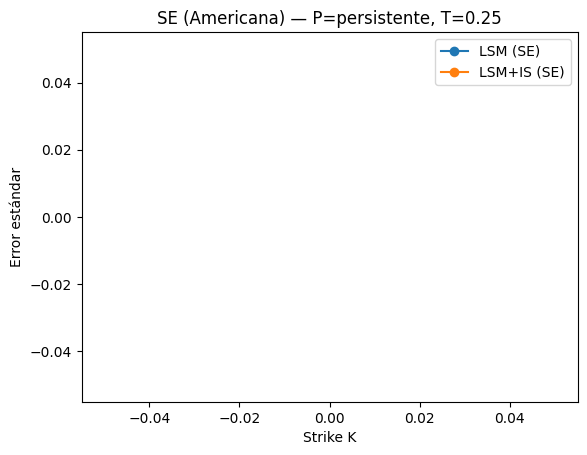

Guardado: outputs\se_americana_P-persistente_T-0.25.png


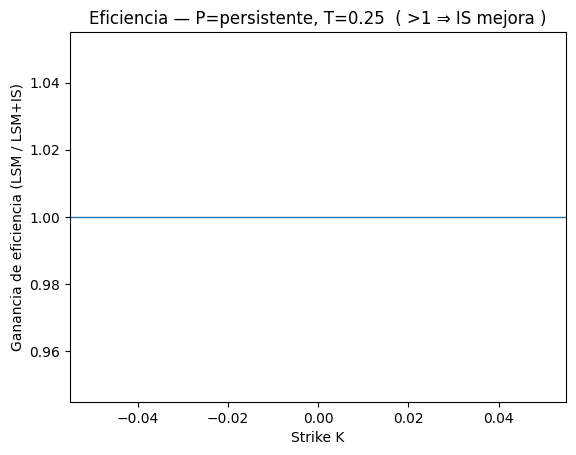

Guardado: outputs\eficiencia_gain_P-persistente_T-0.25.png


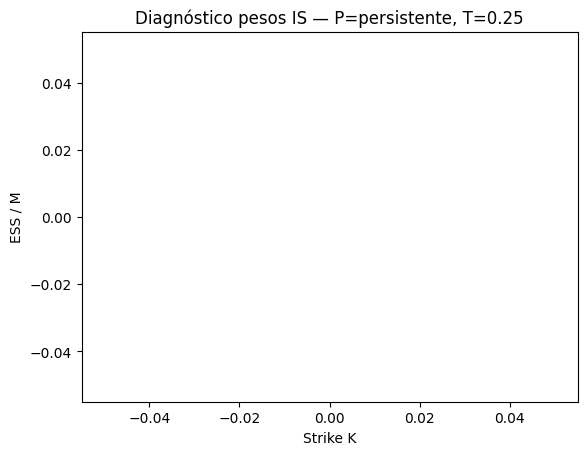

Guardado: outputs\ess_frac_P-persistente_T-0.25.png


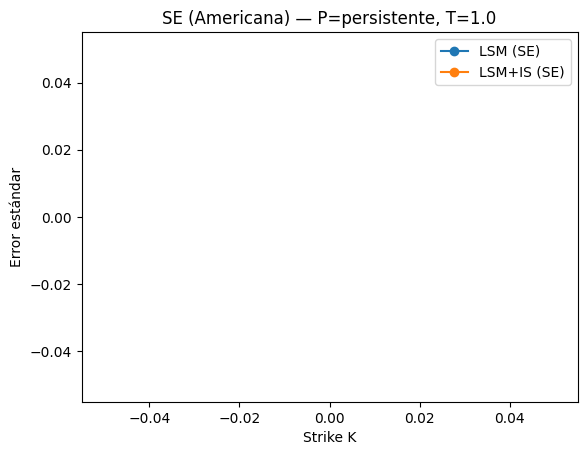

Guardado: outputs\se_americana_P-persistente_T-1.0.png


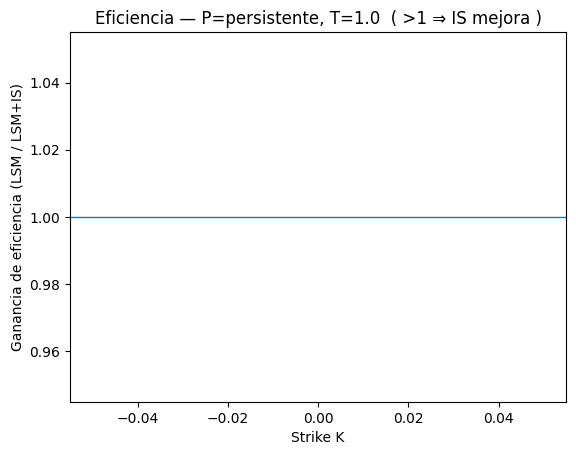

Guardado: outputs\eficiencia_gain_P-persistente_T-1.0.png


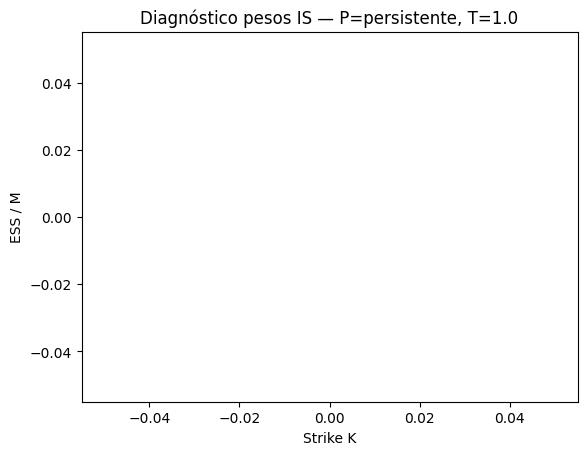

Guardado: outputs\ess_frac_P-persistente_T-1.0.png


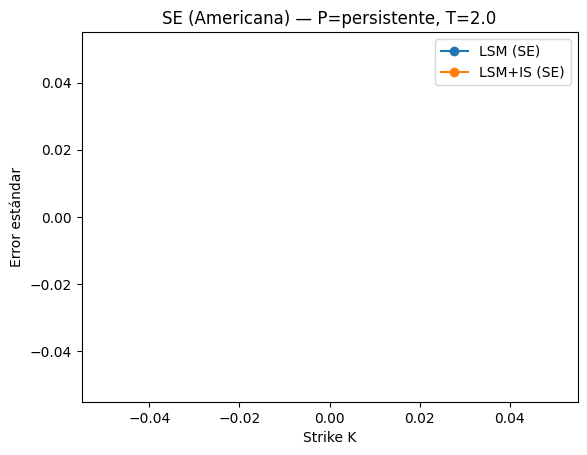

Guardado: outputs\se_americana_P-persistente_T-2.0.png


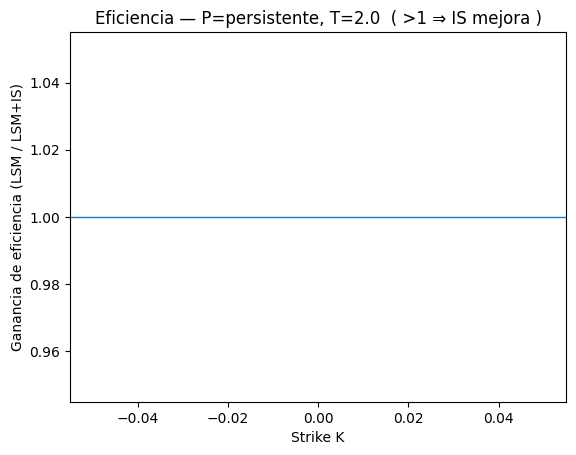

Guardado: outputs\eficiencia_gain_P-persistente_T-2.0.png


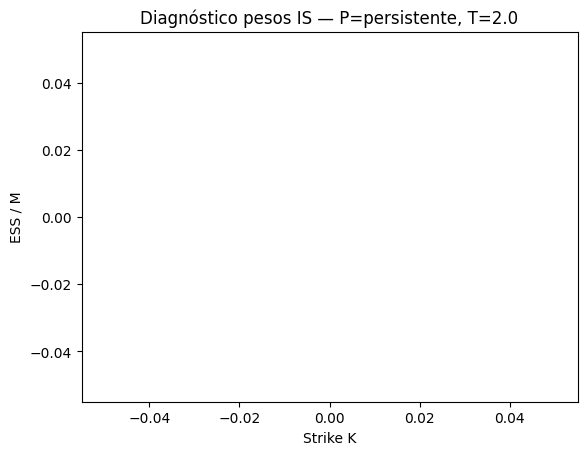

Guardado: outputs\ess_frac_P-persistente_T-2.0.png


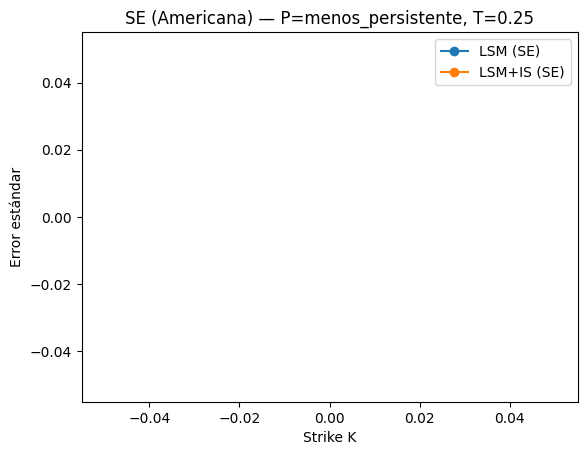

Guardado: outputs\se_americana_P-menos_persistente_T-0.25.png


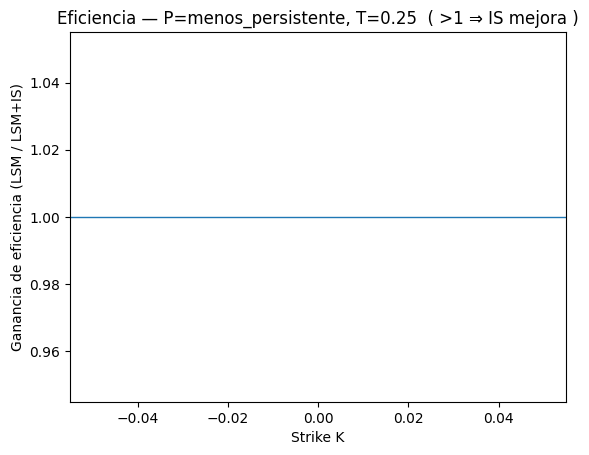

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-0.25.png


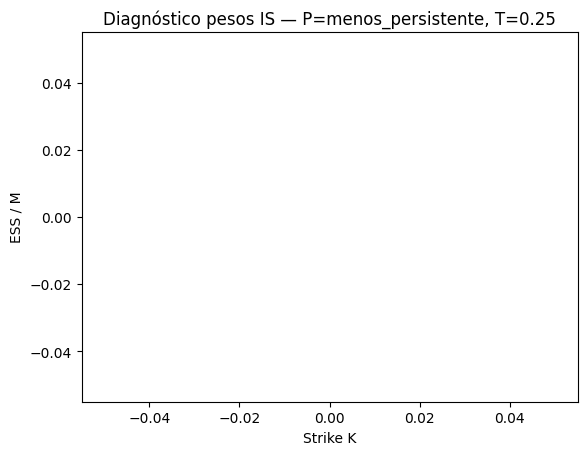

Guardado: outputs\ess_frac_P-menos_persistente_T-0.25.png


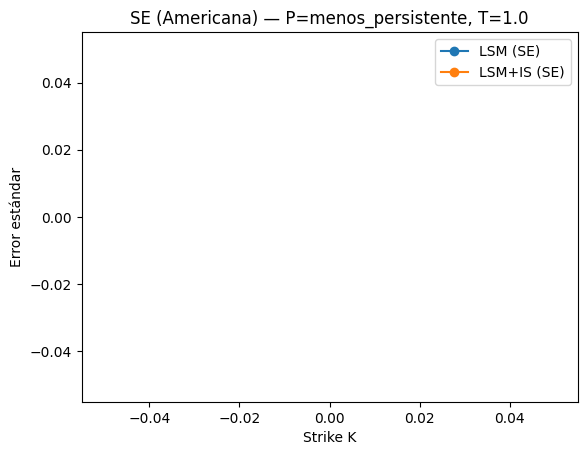

Guardado: outputs\se_americana_P-menos_persistente_T-1.0.png


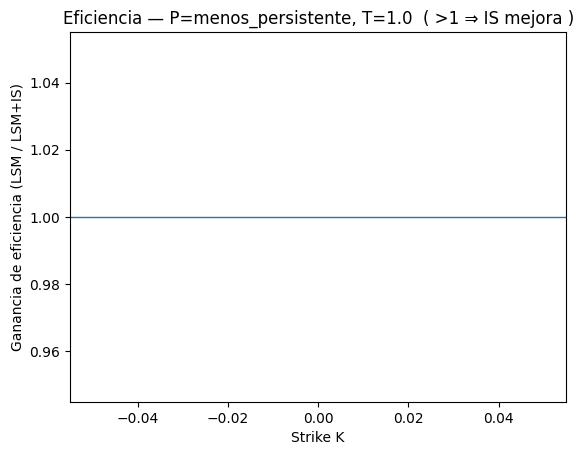

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-1.0.png


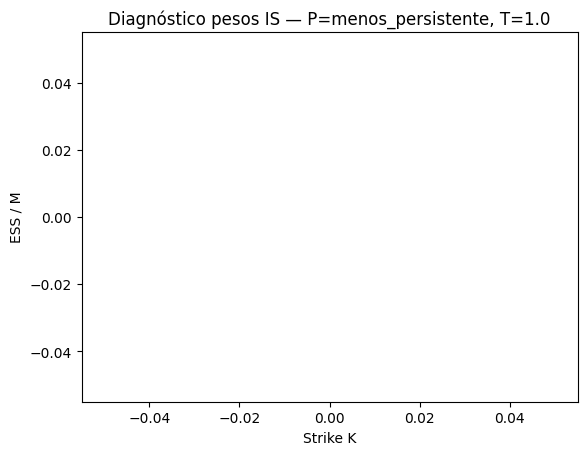

Guardado: outputs\ess_frac_P-menos_persistente_T-1.0.png


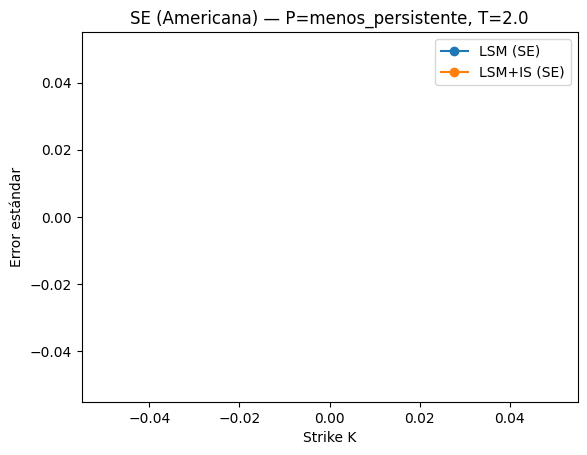

Guardado: outputs\se_americana_P-menos_persistente_T-2.0.png


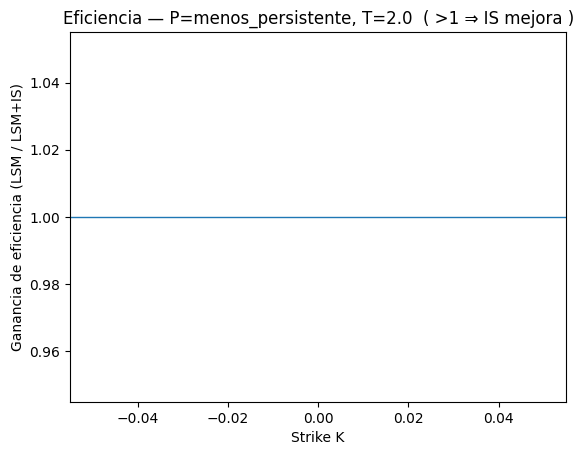

Guardado: outputs\eficiencia_gain_P-menos_persistente_T-2.0.png


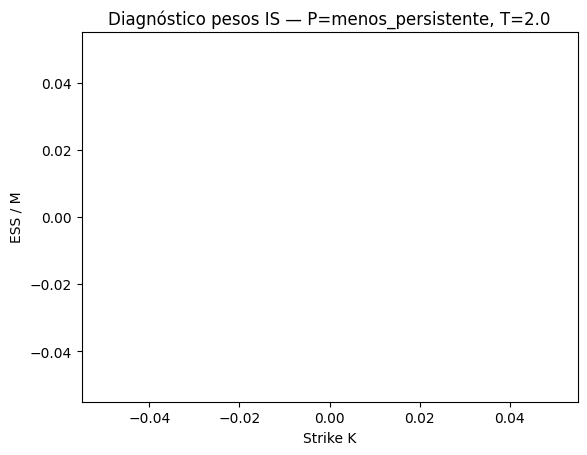

Guardado: outputs\ess_frac_P-menos_persistente_T-2.0.png


In [8]:
# =========================
# 7) Gráficos
# =========================
def plot_se_americana(df, P_name, T):
    d=df[(df.P==P_name)&(df.T==T)].sort_values("K")
    plt.figure()
    plt.plot(d.K, d.AM_LSM_SE, marker="o", label="LSM (SE)")
    plt.plot(d.K, d.AM_LSM_IS_SE, marker="o", label="LSM+IS (SE)")
    plt.xlabel("Strike K"); plt.ylabel("Error estándar")
    plt.title(f"SE (Americana) — P={P_name}, T={T}")
    plt.legend()
    out=OUT_DIR/f"se_americana_P-{P_name}_T-{T}.png"
    plt.savefig(out,dpi=200,bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

def plot_eff_gain(df, P_name, T):
    d=df[(df.P==P_name)&(df.T==T)].sort_values("K")
    plt.figure()
    plt.plot(d.K, d.eff_gain_LSM_over_IS, marker="o")
    plt.axhline(1.0, linewidth=1)
    plt.xlabel("Strike K"); plt.ylabel("Ganancia de eficiencia (LSM / LSM+IS)")
    plt.title(f"Eficiencia — P={P_name}, T={T}  ( >1 ⇒ IS mejora )")
    out=OUT_DIR/f"eficiencia_gain_P-{P_name}_T-{T}.png"
    plt.savefig(out,dpi=200,bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

def plot_ess(df, P_name, T):
    d=df[(df.P==P_name)&(df.T==T)].sort_values("K")
    plt.figure()
    plt.plot(d.K, d.ESS_frac, marker="o")
    plt.xlabel("Strike K"); plt.ylabel("ESS / M")
    plt.title(f"Diagnóstico pesos IS — P={P_name}, T={T}")
    out=OUT_DIR/f"ess_frac_P-{P_name}_T-{T}.png"
    plt.savefig(out,dpi=200,bbox_inches="tight")
    plt.show()
    print("Guardado:", out)

for P_name in Ps:
    for T in Ts:
        plot_se_americana(df,P_name,T)
        plot_eff_gain(df,P_name,T)
        plot_ess(df,P_name,T)


In [9]:
# =========================
# 8) Tabla agregada (resumen)
# =========================
agg = (df.groupby(["P","T"])
         .agg(eff_gain_mean=("eff_gain_LSM_over_IS","mean"),
              eff_gain_median=("eff_gain_LSM_over_IS","median"),
              ess_frac_mean=("ESS_frac","mean"),
              ess_frac_min=("ESS_frac","min"))
         .reset_index())

agg_path=OUT_DIR/"tabla_resumen_agregada.csv"
agg.to_csv(agg_path,index=False)
print("Exportado:", agg_path.resolve())
agg


Exportado: C:\Users\Usuario\GitHub\ucm\TFG\outputs\tabla_resumen_agregada.csv


,P,T,eff_gain_mean,eff_gain_median,ess_frac_mean,ess_frac_min
0,menos_persistente,0.25,0.166390,0.029752,0.204514,0.000037
1,menos_persistente,1.00,0.085835,0.051144,0.003331,0.000049
2,menos_persistente,2.00,0.006932,0.002707,0.002857,0.000020
3,persistente,0.25,0.143367,0.010107,0.213368,0.000023
4,persistente,1.00,0.102189,0.042986,0.024216,0.000020
5,persistente,2.00,0.108700,0.024232,0.001388,0.000020


In [11]:
mask = (df["P"].astype(str).str.strip() == "persistente") & (pd.to_numeric(df["T"], errors="coerce") == 0.25)
df.loc[mask, ["K","lambda","EU_MC","EU_MC_SE","EU_IS","EU_IS_SE","AM_LSM","AM_LSM_SE","AM_LSM_IS","AM_LSM_IS_SE","SE_ratio_IS_over_LSM","eff_gain_LSM_over_IS"]]


,K,lambda,EU_MC,EU_MC_SE,EU_IS,EU_IS_SE,AM_LSM,AM_LSM_SE,AM_LSM_IS,AM_LSM_IS_SE,SE_ratio_IS_over_LSM,eff_gain_LSM_over_IS
0,90.0,-0.700000,11.737741,0.050800,0.000000,0.000000,11.678064,0.039327,17.763455,3.341421,84.964100,0.000065
1,100.0,0.050169,5.373601,0.038230,5.315875,0.025388,5.351340,0.033051,5.273122,0.023584,0.713548,0.553191
2,110.0,0.700000,1.974521,0.024295,1.165518,0.293390,1.977141,0.021828,0.928857,0.131365,6.018072,0.005559
3,120.0,0.700000,0.620541,0.013860,0.473267,0.102605,0.623049,0.012730,0.371111,0.043804,3.441041,0.014655
